### ANALIZA FACTORILOR CARE INFLUENTEAZA PLECAREA ANGAJATILOR

Analiza este realizata pentru departamentul de Resurse Umane astfel incat acestia sa inteleaga ce caracteristici ale angajatilor 
si ce factori legati de mediul de lucru sunt asociati cu plecarea angajatilor din companie. Scopul este de a identifica principalele 
zone in care sunt necesare masuri de retentie si pentru a reduce fluctuatia de personal.

##### INTREBARE PRINCIPALA

Care sunt primii 3 factori asociati cu plecarea angajatilor si ce categorii de angajati au inregistrat cele mai ridicate rate de plecare?

##### INTREBARI SECUNDARE

1.Cum variaza rata de plecare intre categoriile celor 3 factori principali identificati?

2.Care sunt categoriile cu cele mai ridicate rate de plecare in cadrul fiecaruia dintre cei 3 factori principali?

3.Cum se compara rata de plecare a categoriilor identificate cu rata generala de plecare a companiei?

In [1]:
# Importam bibliotecile necesare pentru analiza datelor si vizualizarea rezultatelor.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Incarcam fisierul CSV intr-un DataFrame pandas.

df = pd.read_csv("3.Subject_2-Employee+attrition+CSV.csv")

In [3]:
# Afisam primele 5 randuri pentru a intelege structura datelor.

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
# Verificam tipul fiecarei variabile si numarul de valori nenule.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [5]:
# Calculam numarul de valori lipsa pentru fiecare coloana.

df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [6]:
# Verificam daca exista randuri duplicate in dataset.

df.duplicated().sum()

np.int64(0)

In [7]:
# Verificam numarul de angajati pentru fiecare valoare a variabilei Attrition.

df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [8]:
# Calculam procentul pentru rata generala de plecare. Aceasta rata va fi folosita ca punct de referinta
# pentru comparatiile ulterioare.

Attrition_rate = round((df["Attrition"] == "Yes").mean() * 100,2)

Attrition_rate

np.float64(16.12)

In [9]:
# Cream o variabila numerica pentru coloana Attrition. Pentru anumite analize statistice vom avea nevoie de valori numerice.
# 1 = angajatul a plecat
# 0 = angajatul a ramas

df["Attrition_Category"] = df["Attrition"].map({
    "Yes": 1,
    "No": 0
})

In [10]:
# Identificam variabilele categorice
# Cream lista pentru a putea analiza automat toate variabilele categorice si pentru a calcula rata de plecare pentru fiecare categorie.

categorical_features = [
    column for column in df.select_dtypes(include="object").columns
    if column != "Attrition"
]

categorical_features

['BusinessTravel',
 'Department',
 'EducationField',
 'Gender',
 'JobRole',
 'MaritalStatus',
 'Over18',
 'OverTime']

In [11]:
# Cream o lista goala in care vom salva rezultatele pentru fiecare variabila categorica analizata.

categorical_results = []

In [12]:
# Parcurgem fiecare variabila categorica.
# Pentru fiecare categorie calculam:
# - numarul total de angajati;
# - numarul angajatilor care au plecat;
# - rata de plecare.

for column in categorical_features:

    result = df.groupby(column)["Attrition_Category"].agg(
        ["count", "sum", "mean"]
    ).reset_index()

    # Redenumim coloanele

    result = result.rename(columns={
        column: "Category",
        "count": "Total_employees",
        "sum": "Former_employees",
        "mean": "Mean"
    })

    # Transformam rata de plecare din proportie in procent.

    result["Attrition_Rate"] = result["Mean"] * 100

    # Adaugam numele variabilei analizate.

    result["Factor"] = column

    # Salvam rezultatul in lista.

    categorical_results.append(result)

In [13]:
# Combinam rezultatele tuturor variabilelor categorice intr-un singur DataFrame.

categorical_analysis = pd.concat(
    categorical_results,
    ignore_index=True
)

In [14]:
# Calculam diferenta dintre rata de plecare a fiecarei categorii si rata generala de plecare a companiei.
# O valoare pozitiva indica o rata de plecare mai mare decat media companiei.
# O valoare negativa indica o rata de plecare mai mica decat media companiei.

categorical_analysis["Difference_from_overall"] = (
    categorical_analysis["Attrition_Rate"] - Attrition_rate
)

In [15]:
# Sortam toate categoriile descrescator dupa rata de plecare.
# Acest rezultat ne ajuta sa identificam categoriile cu cele mai ridicate rate de plecare.

top_categories = categorical_analysis.sort_values(
    by="Attrition_Rate",
    ascending=False
)


top_categories[
    [
        "Factor",
        "Category",
        "Total_employees",
        "Former_employees",
        "Attrition_Rate"
    ]
].head(10).round({"Attrition_Rate": 2})

,Factor,Category,Total_employees,Former_employees,Attrition_Rate
22,JobRole,Sales Representative,83,33,39.76
28,OverTime,Yes,416,127,30.53
6,EducationField,Human Resources,27,7,25.93
25,MaritalStatus,Single,470,120,25.53
1,BusinessTravel,Travel_Frequently,277,69,24.91
11,EducationField,Technical Degree,132,32,24.24
16,JobRole,Laboratory Technician,259,62,23.94
15,JobRole,Human Resources,52,12,23.08
8,EducationField,Marketing,159,35,22.01
5,Department,Sales,446,92,20.63


In [16]:
# In urma acestui rezultat vom analiza variatia ratei de plecare intre categoriile fiecarui factor, nu doar categoria cu cea mai mare rata, 
# astfel incat sa putem identifica factorii care prezinta diferente mai mari intre categoriile lor.

In [17]:
# Pentru fiecare factor calculam:
# - rata minima de plecare dintre categoriile sale;
# - rata maxima de plecare dintre categoriile sale.

factor_analysis = categorical_analysis.groupby("Factor").agg(
    Min_Attrition_Rate=("Attrition_Rate", "min"),
    Max_Attrition_Rate=("Attrition_Rate", "max")
)

# Calculam diferenta dintre rata maxima si rata minima pentru fiecare factor.
# O diferenta mai mare indica o variatie mai mare a ratei de plecare intre categoriile aceluiasi factor.

factor_analysis["Attrition_Range"] = (
    factor_analysis["Max_Attrition_Rate"]
    - factor_analysis["Min_Attrition_Rate"]
)

# Ordonam factorii descrescator in functie de variatia ratei de plecare dintre categoriile lor.

factor_analysis = factor_analysis.sort_values(
    by="Attrition_Range",
    ascending=False
)

factor_analysis.round(2)

,Min_Attrition_Rate,Max_Attrition_Rate,Attrition_Range
Factor,,,
JobRole,2.50,39.76,37.26
OverTime,10.44,30.53,20.09
BusinessTravel,8.00,24.91,16.91
MaritalStatus,10.09,25.53,15.44
EducationField,13.41,25.93,12.51
Department,13.84,20.63,6.79
Gender,14.80,17.01,2.21
Over18,16.12,16.12,0.00


In [18]:
# Selectam primii 3 factori care prezinta cea mai mare variatie a ratei de plecare intre categoriile lor.

top_3_factors = factor_analysis.head(3)

top_3_factors.round(2)

,Min_Attrition_Rate,Max_Attrition_Rate,Attrition_Range
Factor,,,
JobRole,2.50,39.76,37.26
OverTime,10.44,30.53,20.09
BusinessTravel,8.00,24.91,16.91


### Intrebarea secundara 1: Cum variaza rata de plecare intre categoriile celor 3 factori principali?

### Analiza factorului JobRole

In [19]:
# Selectam din tabelul de analiza doar categoriile care apartin factorului JobRole.

jobrole_data = categorical_analysis[
    categorical_analysis["Factor"] == "JobRole"
]

In [20]:
# Afisam rata de plecare pentru fiecare categorie de JobRole.

jobrole_data[
    [
        "Category",
        "Total_employees",
        "Former_employees",
        "Attrition_Rate",
        "Difference_from_overall"
    ]
].sort_values(
    by="Attrition_Rate",
    ascending=False
).round({
    "Attrition_Rate": 2,
    "Difference_from_overall": 2
})

,Category,Total_employees,Former_employees,Attrition_Rate,Difference_from_overall
22,Sales Representative,83,33,39.76,23.64
16,Laboratory Technician,259,62,23.94,7.82
15,Human Resources,52,12,23.08,6.96
21,Sales Executive,326,57,17.48,1.36
20,Research Scientist,292,47,16.10,-0.02
18,Manufacturing Director,145,10,6.90,-9.22
14,Healthcare Representative,131,9,6.87,-9.25
17,Manager,102,5,4.90,-11.22
19,Research Director,80,2,2.50,-13.62


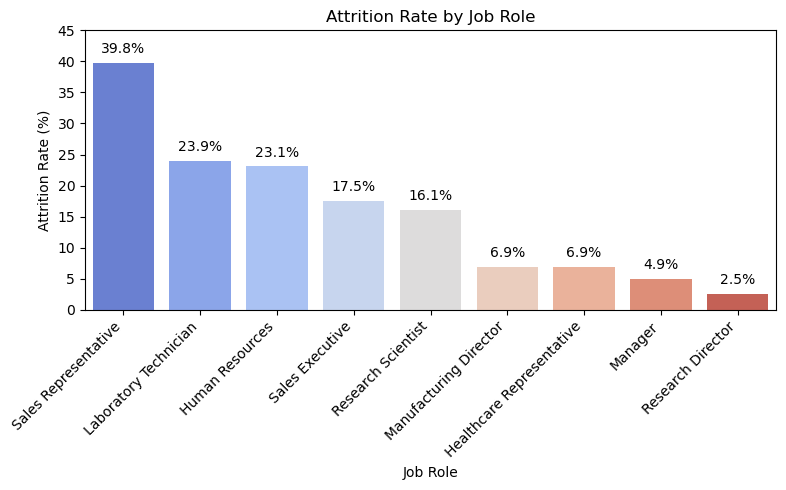

In [21]:
plt.figure(figsize=(8, 5))

jobrole_sorted = jobrole_data.sort_values(
    "Attrition_Rate",
    ascending=False
)

ax = sns.barplot(
    data=jobrole_sorted,
    x="Category",
    y="Attrition_Rate",
    hue="Category",
    palette="coolwarm",
    legend=False,
    errorbar=None
)

# Afisam procentele deasupra tuturor barelor.

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=5
    )

plt.title("Attrition Rate by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Attrition Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 45)
plt.tight_layout()

plt.show()


### Analiza factorului OverTime

In [22]:
# Selectam din tabelul de analiza doar categoriile care apartin factorului OverTime.

overtime_data = categorical_analysis[
    categorical_analysis["Factor"] == "OverTime"
]

In [23]:
# Afisam rata de plecare pentru angajatii care fac sau nu ore suplimentare.

overtime_data[
    [
        "Category",
        "Total_employees",
        "Former_employees",
        "Attrition_Rate",
        "Difference_from_overall"
    ]
].sort_values(
    by="Attrition_Rate",
    ascending=False
).round({
    "Attrition_Rate": 2,
    "Difference_from_overall": 2
})

,Category,Total_employees,Former_employees,Attrition_Rate,Difference_from_overall
28,Yes,416,127,30.53,14.41
27,No,1054,110,10.44,-5.68


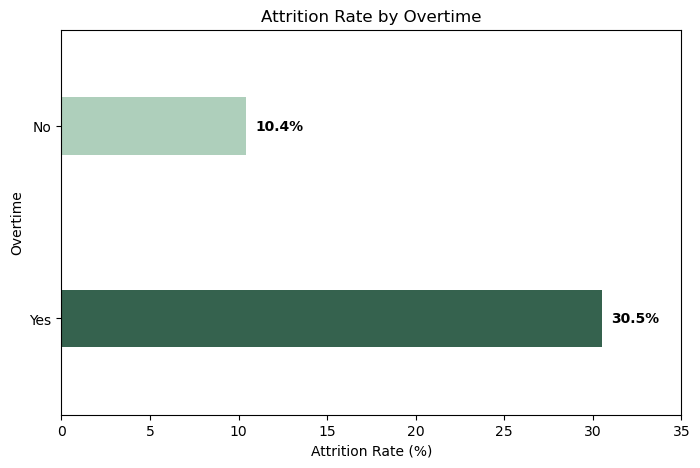

In [24]:
# Cream un grafic pentru compararea ratei de plecare intre angajatii care fac overtime si cei care nu fac.

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=overtime_data,
    x="Attrition_Rate",
    y="Category",
    hue="Category",
    palette=["#A8D5BA", "#2D6A4F"],
    width=0.3,
    errorbar=None,
    legend=False
)

# Adaugam procentele deasupra fiecarei bare.

for bar in ax.patches:
    width = bar.get_width()
    
    if width > 0:
        ax.text(
            width + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va="center",
            fontsize=10,
            weight="bold"
        )

plt.title("Attrition Rate by Overtime")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Overtime")

plt.xlim(0, 35)

plt.show()

### Analiza factorului BusinessTravel

In [25]:
# Selectam din tabelul de analiza doar categoriile care apartin factorului BusinessTravel.

travel_data = categorical_analysis[
    categorical_analysis["Factor"] == "BusinessTravel"
]

In [26]:
# Afisam rata de plecare pentru fiecare categorie de BusinessTravel.

travel_data[
    [
        "Category",
        "Total_employees",
        "Former_employees",
        "Attrition_Rate",
        "Difference_from_overall"
    ]
].sort_values(
    by="Attrition_Rate",
    ascending=False
).round({
    "Attrition_Rate": 2,
    "Difference_from_overall": 2
})

,Category,Total_employees,Former_employees,Attrition_Rate,Difference_from_overall
1,Travel_Frequently,277,69,24.91,8.79
2,Travel_Rarely,1043,156,14.96,-1.16
0,Non-Travel,150,12,8.00,-8.12


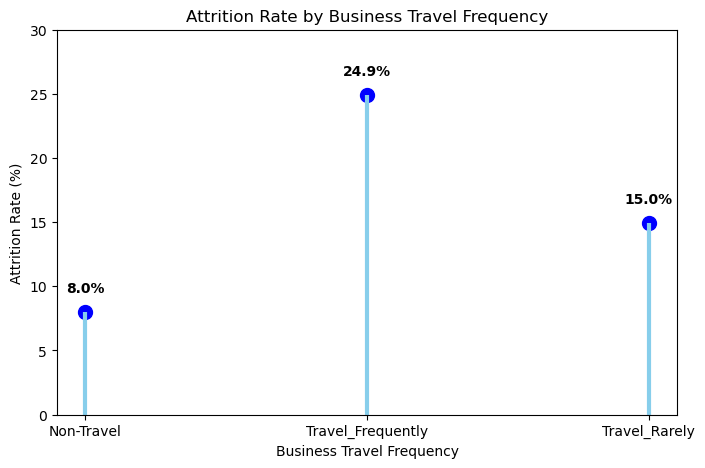

In [27]:
# Cream un grafic pentru compararea ratei de plecare in functie de frecventa deplasarilor in interes de serviciu.
plt.figure(figsize=(8, 5))

plt.vlines(
    travel_data["Category"],
    0,
    travel_data["Attrition_Rate"],
    color="skyblue",
    linewidth=3
)

plt.scatter(
    travel_data["Category"],
    travel_data["Attrition_Rate"],
    color="blue",
    s=100
)

for x, y in zip(travel_data["Category"], travel_data["Attrition_Rate"]):
    plt.text(
        x,
        y + 1.5,
        f"{y:.1f}%",
        ha="center",
        fontsize=10,
        weight="bold"
)
    
plt.ylim(0,30)
plt.title("Attrition Rate by Business Travel Frequency")
plt.xlabel("Business Travel Frequency")
plt.ylabel("Attrition Rate (%)")

plt.show()

### Intrebarea secundara 2:Care sunt categoriile cu cele mai ridicate rate de plecare in cadrul fiecaruia dintre cei 3 factori principali?

In [28]:
# Selectam categoria cu cea mai mare rata de plecare pentru fiecare dintre cei 3 factori
# si ordonam categoriile descrescator dupa rata de plecare.
top_categories_by_factor = categorical_analysis[
    categorical_analysis["Factor"].isin(
        ["JobRole", "OverTime", "BusinessTravel"]
    )
].sort_values(
    "Attrition_Rate",
    ascending=False
).groupby(
    "Factor"
).head(1)

top_categories_by_factor[
    [
        "Factor",
        "Category",
        "Total_employees",
        "Former_employees",
        "Attrition_Rate"
    ]
].round({"Attrition_Rate": 2})

,Factor,Category,Total_employees,Former_employees,Attrition_Rate
22,JobRole,Sales Representative,83,33,39.76
28,OverTime,Yes,416,127,30.53
1,BusinessTravel,Travel_Frequently,277,69,24.91


### Intrebarea secundara 3: Cum se compara rata de plecare a categoriilor identificate cu rata generala de plecare a companiei?

In [29]:
# Selectam categoriile identificate si pastram doar coloanele necesare pentru comparatie.

comparison_with_overall = top_categories_by_factor[
    [
        "Factor",
        "Category",
        "Attrition_Rate",
        "Difference_from_overall"
    ]
].copy()

# Adaugam rata generala de plecare a companiei pentru a putea face comparatia.
comparison_with_overall["Overall_Attrition_Rate"] = Attrition_rate

# Afisam rezultatul final
comparison_with_overall[
    [
        "Factor",
        "Category",
        "Attrition_Rate",
        "Overall_Attrition_Rate",
        "Difference_from_overall"
    ]
].round(2)

,Factor,Category,Attrition_Rate,Overall_Attrition_Rate,Difference_from_overall
22,JobRole,Sales Representative,39.76,16.12,23.64
28,OverTime,Yes,30.53,16.12,14.41
1,BusinessTravel,Travel_Frequently,24.91,16.12,8.79


### CONCLUZII

Rata generala de plecare din companie este de 16.12%.

Analiza a identificat trei factori care prezinta cele mai mari diferente intre categoriile lor in ceea ce priveste 
rata de plecare: JobRole, OverTime si BusinessTravel.

In cadrul acestor factori, cele mai ridicate rate de plecare au fost inregistrate pentru Sales Representative (39.76%), 
angajatii care lucreaza OverTime (30.53%) si angajatii care calatoresc Travel_Frequently (24.91%).

Toate cele trei categorii au inregistrat rate de plecare peste rata generala de 16.12%, diferentele fiind 
de 23.64, 14.41 si 8.79 puncte procentuale.